# 01 · EDA of Source 2: SmellNet-Base

**What this notebook does.** It checks the SmellNet-Base files (50 substances × 6 days, 6 gas channels at 1 Hz), the official train/test split (days 1–5 / day 6), recording lengths, and the GC-MS vectors shipped with the dataset. SmellNet contains no coffee; in this project it is (i) a second MOX gas-sensor dataset to fuse with S1 (Experiment B) and (ii) the testbed for sensor + GC-MS fusion (Experiment D).

In [1]:
import sys, os
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 30)
FIG = ROOT / 'results' / 'figures'

In [2]:
from src.data.loaders import load_s2_sessions, load_s2_gcms, S2_CHANNELS
S = load_s2_sessions()
meta = pd.DataFrame([{'substance': s['substance'], 'day': s['day'], 'split': s['split'], 'length': len(s['data'])} for s in S])
print('sessions:', len(meta), '| substances:', meta.substance.nunique(), '| channels:', S2_CHANNELS)
print(meta.groupby('split').agg(sessions=('day', 'size'), days=('day', lambda d: sorted(d.unique()))))
meta.length.describe().round(1)

sessions: 300 | substances: 50 | channels: ['NO2', 'C2H5OH', 'VOC', 'CO', 'Alcohol', 'LPG']
          sessions             days
split                              
testing         50              [6]
training       250  [1, 2, 3, 4, 5]


count    300.0
mean     602.4
std       42.4
min      517.0
25%      580.0
50%      600.0
75%      614.0
max      867.0
Name: length, dtype: float64

**Reading the output.** 300 sessions = 50 substances × 6 days, one CSV each; days 1–5 are in `training/` and day 6 in `testing/`. Sessions last 517–867 s (median 600 s).

In [3]:
A = np.concatenate([s['data'] for s in S])
pd.DataFrame({'min': A.min(0), 'median': np.median(A, 0), 'max': A.max(0)}, index=S2_CHANNELS)

,min,median,max
NO2,13.0,46.0,775.0
C2H5OH,39.0,76.0,863.0
VOC,26.0,105.0,953.0
CO,705.0,776.0,1006.0
Alcohol,0.0,2.0,42.0
LPG,2.0,23.0,507.0


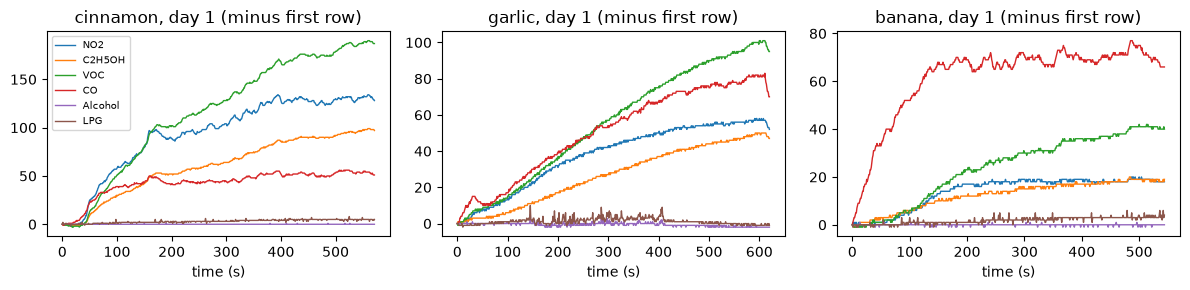

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3), sharey=False)
for ax, sub in zip(axes, ['cinnamon', 'garlic', 'banana']):
    s = next(x for x in S if x['substance'] == sub and x['day'] == 1)
    for c in range(6): ax.plot(s['data'][:, c] - s['data'][0, c], lw=1, label=S2_CHANNELS[c])
    ax.set_title(f'{sub}, day 1 (minus first row)'); ax.set_xlabel('time (s)')
axes[0].legend(fontsize=7); plt.tight_layout(); plt.savefig(FIG / 'eda_s2_examples.png', dpi=130); plt.show()

**Polarity.** Unlike S1's resistance, SmellNet's raw readings *rise* when the odour is present. For the S1 + S2 fusion we therefore convert S1 to conductance (G = 1/R), which also rises with gas.

In [5]:
G = load_s2_gcms('spec'); Ga = load_s2_gcms('atom')
print('Xspec:', G.shape, '| Xatom:', Ga.shape, '| same 50 substances:', set(G.index) == set(Ga.index) == set(meta.substance))
Ga.head()

Xspec: (50, 460) | Xatom: (50, 17) | same 50 substances: True


,C,Ca,Cl,Co,Cr,Fe,H,K,Mg,Mn,N,Na,O,P,S,V,Zn
food_name,,,,,,,,,,,,,,,,,
allspice,74185.450,714.867,0.0,0.0,0.0,0.0,91627.400,1082.25,269.0,0.0,0.00,0.0,10073.250,0.0,0.0,0.0,0.0
almond,1043090.978,0.000,0.0,0.0,0.0,0.0,1884082.582,0.00,0.0,0.0,13973.55,0.0,166446.691,0.0,0.0,0.0,0.0
angelica,1028.145,0.000,0.0,0.0,0.0,0.0,685.430,0.00,0.0,0.0,0.00,0.0,452.787,0.0,0.0,0.0,0.0
apple,136503.756,0.000,0.0,0.0,0.0,0.0,362821.152,272.70,0.0,0.0,990.00,0.0,176140.238,0.0,0.0,0.0,0.0
asparagus,78660.410,0.000,0.0,0.0,0.0,0.0,277045.210,705.20,0.0,0.0,7726.98,0.0,103745.497,0.0,0.0,0.0,0.0


**GC-MS is class-level.** There is exactly one GC-MS vector per substance, derived from the FooDB database, not measured per session. If a model received the GC-MS vector of a test sample's (true) substance, it would be handed the answer. Experiment D therefore uses GC-MS only during training, or as the fixed prototypes of *all* 50 classes.